# Laborator 3 - Retele Bayesiene

### Variabile si Structura Retelei
- S: Spam (1) / Non-spam (0)
- O: Contine "oferta" (1/0)
- L: Contine linkuri (1/0)
- M: Lungime mare (1/0)

DAG: S -> O, S -> L, S -> M, L -> M
Parinti: Pa(S) = {}, Pa(O) = {S}, Pa(L) = {S}, Pa(M) = {S, L}

Factorizare:
P(S, O, L, M) = P(S) * P(O | S) * P(L | S) * P(M | S, L)


## Cerinta a) Independente in retea

Conform proprietatii locale Markov si criteriului de d-separare:

### 1. Independente conditionate unice:
1. **O _|_ L | S** (stiind clasa S, prezenta ofertei si prezenta linkurilor devin independente)
2. **O _|_ M | S** (stiind S, oferta si lungimea devin independente)
3. **O _|_ M | (S, L)** (adaugarea lui L la setul de conditionare pastreaza blocata calea)
4. **O _|_ L | (S, M)** (adaugarea lui M la setul de conditionare pastreaza calea blocata de S)

Sub forma compacta (Markov Blanket):
- **O _|_ (L, M) | S** (stiind parintele direct S, nodul O este complet izolat de restul retelei)

### Observatii structurale:
- **Fara independente marginale**: Fara conditionare (la nivel a priori), toate nodurile depind de S, deci nu exista independente neconditionate.
- **Conexiuni directe**: Intre perechile (S, O), (S, L), (S, M) si (L, M) exista arce directe, asadar ele nu pot fi independente sub nicio conditionare.
- **Relatia de simetrie**: Orice afirmatie de tipul X _|_ Y | Z implica automat Y _|_ X | Z.

## Cerinta b) Clasificare e-mail-uri (O, L, M)

Regula Bayes MAP:
arg max_s P(S = s | O, L, M) = arg max_s P(S = s, O, L, M)

P(S=1 | O, L, M) = P(S=1, O, L, M) / [P(S=1, O, L, M) + P(S=0, O, L, M)]
Daca P(S=1 | O, L, M) > 0.5 -> Spam, altfel Non-Spam.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

P_S = {1: 0.4, 0: 0.6}

P_O_given_S = {
    (1, 1): 0.7, (0, 1): 0.3,
    (1, 0): 0.1, (0, 0): 0.9
}

P_L_given_S = {
    (1, 1): 0.8, (0, 1): 0.2,
    (1, 0): 0.3, (0, 0): 0.7
}

P_M_given_SL = {
    (1, 1, 1): 0.9, (0, 1, 1): 0.1,
    (1, 1, 0): 0.5, (0, 1, 0): 0.5,
    (1, 0, 1): 0.6, (0, 0, 1): 0.4,
    (1, 0, 0): 0.2, (0, 0, 0): 0.8
}

rows = []
for o in [0, 1]:
    for l in [0, 1]:
        for m in [0, 1]:
            p1 = P_S[1] * P_O_given_S[(o, 1)] * P_L_given_S[(l, 1)] * P_M_given_SL[(m, 1, l)]
            p0 = P_S[0] * P_O_given_S[(o, 0)] * P_L_given_S[(l, 0)] * P_M_given_SL[(m, 0, l)]
            post1 = p1 / (p1 + p0)
            rows.append({
                'O': o, 'L': l, 'M': m,
                'P(S=1, O, L, M)': round(p1, 4),
                'P(S=0, O, L, M)': round(p0, 4),
                'P(S=1 | O, L, M)': round(post1, 4),
                'Decizie': 'Spam' if post1 > 0.5 else 'Non-Spam'
            })

df = pd.DataFrame(rows)
display(df)


,O,L,M,"P(S=1, O, L, M)","P(S=0, O, L, M)","P(S=1 | O, L, M)",Decizie
0,0,0,0,0.0120,0.3024,0.0382,Non-Spam
1,0,0,1,0.0120,0.0756,0.1370,Non-Spam
2,0,1,0,0.0096,0.0648,0.1290,Non-Spam
3,0,1,1,0.0864,0.0972,0.4706,Non-Spam
4,1,0,0,0.0280,0.0336,0.4545,Non-Spam
5,1,0,1,0.0280,0.0084,0.7692,Spam
6,1,1,0,0.0224,0.0072,0.7568,Spam
7,1,1,1,0.2016,0.0108,0.9492,Spam


### Concluzie si Regula de Decizie

Un e-mail este clasificat Spam daca si numai daca contine "oferta" (O=1) si cel putin o alta caracteristica (L=1 sau M=1):
Decizie = Spam <=> O = 1 si (L = 1 sau M = 1)
In rest: Non-Spam.


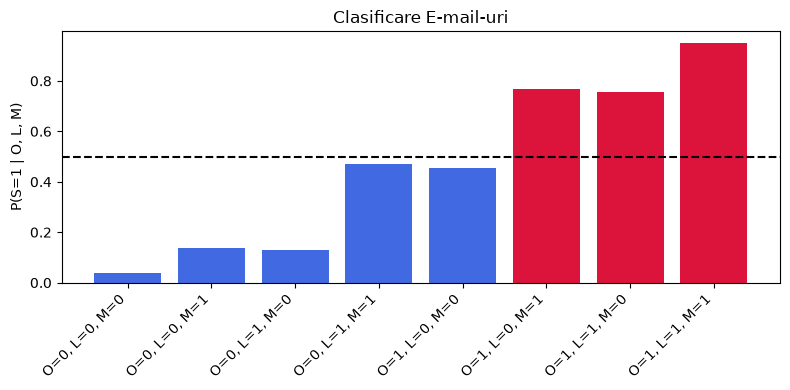

In [2]:
plt.figure(figsize=(8, 4))
labels = [f"O={r['O']}, L={r['L']}, M={r['M']}" for _, r in df.iterrows()]
colors = ['crimson' if d == 'Spam' else 'royalblue' for d in df['Decizie']]
plt.bar(labels, df['P(S=1 | O, L, M)'], color=colors)
plt.axhline(0.5, color='black', linestyle='--')
plt.ylabel('P(S=1 | O, L, M)')
plt.xticks(rotation=45, ha='right')
plt.title('Clasificare E-mail-uri')
plt.tight_layout()
plt.show()
